In [1]:
!pip install ucimlrepo -q

In [2]:
from ucimlrepo import fetch_ucirepo

# Fetch UCI Phishing Websites dataset
phishing_websites = fetch_ucirepo(id=327)

# Features
X = phishing_websites.data.features

# Target
y = phishing_websites.data.targets

print("Dataset loaded successfully!")
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Dataset loaded successfully!
Features shape: (11055, 30)
Target shape: (11055, 1)


In [3]:
print("Feature columns:")
print(X.columns.tolist())

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget values:")
print(y.head())

Feature columns:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']

First 5 rows:


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1



Target values:
   result
0      -1
1      -1
2      -1
3      -1
4       1


In [4]:
# Step 4: Basic Dataset Information

print("Dataset Information:")
print("--------------------")

print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature Data Types:")
print(X.dtypes)

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nDuplicate Rows:")
print(X.duplicated().sum())

Dataset Information:
--------------------
Number of rows: 11055
Number of features: 30

Feature Data Types:
having_ip_address             int64
url_length                    int64
shortining_service            int64
having_at_symbol              int64
double_slash_redirecting      int64
prefix_suffix                 int64
having_sub_domain             int64
sslfinal_state                int64
domain_registration_length    int64
favicon                       int64
port                          int64
https_token                   int64
request_url                   int64
url_of_anchor                 int64
links_in_tags                 int64
sfh                           int64
submitting_to_email           int64
abnormal_url                  int64
redirect                      int64
on_mouseover                  int64
rightclick                    int64
popupwindow                   int64
iframe                        int64
age_of_domain                 int64
dnsrecord                   

In [5]:
# Step 5: Target Class Distribution

print("Target Class Distribution:")
print(y['result'].value_counts())

print("\nTarget Class Percentages:")
print(y['result'].value_counts(normalize=True) * 100)

Target Class Distribution:
result
 1    6157
-1    4898
Name: count, dtype: int64

Target Class Percentages:
result
 1    55.694256
-1    44.305744
Name: proportion, dtype: float64


In [6]:
# Step 6: Check Duplicate Records in Detail

# Combine features and target
df = X.copy()
df['result'] = y['result'].values

print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

# Check whether duplicate feature rows have different target values
duplicate_features = df.duplicated(
    subset=X.columns,
    keep=False
)

duplicate_data = df[duplicate_features]

print("\nNumber of rows involved in duplicate feature records:",
      len(duplicate_data))

print("\nTarget distribution among duplicate feature records:")
print(duplicate_data['result'].value_counts())

Total rows: 11055
Duplicate rows: 5206

Number of rows involved in duplicate feature records: 7884

Target distribution among duplicate feature records:
result
 1    4935
-1    2949
Name: count, dtype: int64


In [7]:
# Step 7: Check Conflicting Duplicate Labels

conflicting_duplicates = (
    duplicate_data
    .groupby(list(X.columns))['result']
    .nunique()
)

print("Duplicate feature groups with conflicting target labels:",
      (conflicting_duplicates > 1).sum())

Duplicate feature groups with conflicting target labels: 64


In [11]:
# Step 8: Data Cleaning

import pandas as pd

# Create a complete dataframe
df = X.copy()
df['result'] = y['result'].values

print("Original dataset shape:", df.shape)

# 1. Remove exact duplicate records
df_clean = df.drop_duplicates().copy()

print("\nAfter removing exact duplicates:")
print("Shape:", df_clean.shape)

# 2. Find feature combinations with conflicting labels
feature_columns = X.columns.tolist()

label_counts = (
    df_clean
    .groupby(feature_columns)['result']
    .nunique()
)

conflicting_features = label_counts[label_counts > 1].index

print("\nConflicting feature groups:", len(conflicting_features))

# 3. Remove records with conflicting labels
if len(conflicting_features) > 0:

    conflicting_index = pd.MultiIndex.from_frame(
        df_clean[feature_columns]
    ).isin(conflicting_features)

    df_clean = df_clean[~conflicting_index].copy()

print("\nFinal cleaned dataset shape:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

Original dataset shape: (11055, 31)

After removing exact duplicates:
Shape: (5849, 31)

Conflicting feature groups: 64

Final cleaned dataset shape: (5721, 31)
Remaining duplicate rows: 0
Missing values: 0


In [12]:
# Step 9: Cleaned Class Distribution

print("Cleaned Target Distribution:")
print(df_clean['result'].value_counts())

print("\nCleaned Target Percentages:")
print(
    df_clean['result']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Cleaned Target Distribution:
result
-1    2955
 1    2766
Name: count, dtype: int64

Cleaned Target Percentages:
result
-1    51.65
 1    48.35
Name: proportion, dtype: float64


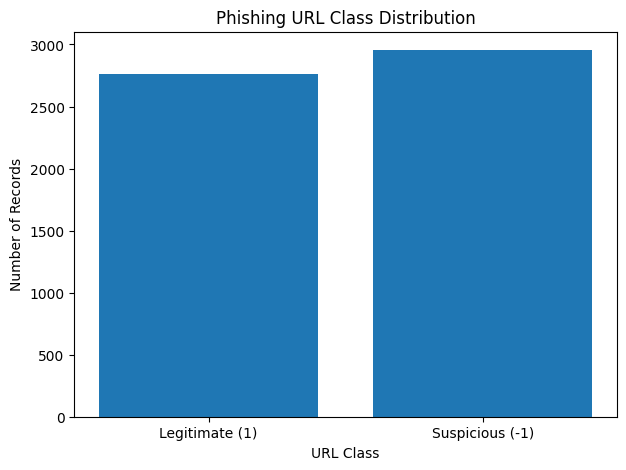

In [13]:
# Step 10: Class Distribution Visualization

import matplotlib.pyplot as plt

class_counts = df_clean['result'].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ['Legitimate (1)', 'Suspicious (-1)'],
    [class_counts.get(1, 0), class_counts.get(-1, 0)]
)

plt.title('Phishing URL Class Distribution')
plt.xlabel('URL Class')
plt.ylabel('Number of Records')
plt.show()

In [14]:
# Step 11: Save Cleaned Dataset

df_clean.to_csv('phishing_cleaned.csv', index=False)

print("Cleaned dataset saved successfully!")
print("File name: phishing_cleaned.csv")
print("Shape:", df_clean.shape)

Cleaned dataset saved successfully!
File name: phishing_cleaned.csv
Shape: (5721, 31)


In [15]:
# Step 12: Feature Correlation with Target

import pandas as pd
import matplotlib.pyplot as plt

# Calculate correlation with target
correlations = df_clean.corr(numeric_only=True)['result'].drop('result')

# Sort by absolute correlation
top_features = correlations.abs().sort_values(ascending=False).head(10)

print("Top 10 Features by Absolute Correlation:")
print(top_features)

Top 10 Features by Absolute Correlation:
sslfinal_state                0.709765
url_of_anchor                 0.687107
prefix_suffix                 0.386242
having_sub_domain             0.302746
web_traffic                   0.286628
sfh                           0.286143
links_in_tags                 0.248927
request_url                   0.242663
domain_registration_length    0.223581
google_index                  0.119731
Name: result, dtype: float64


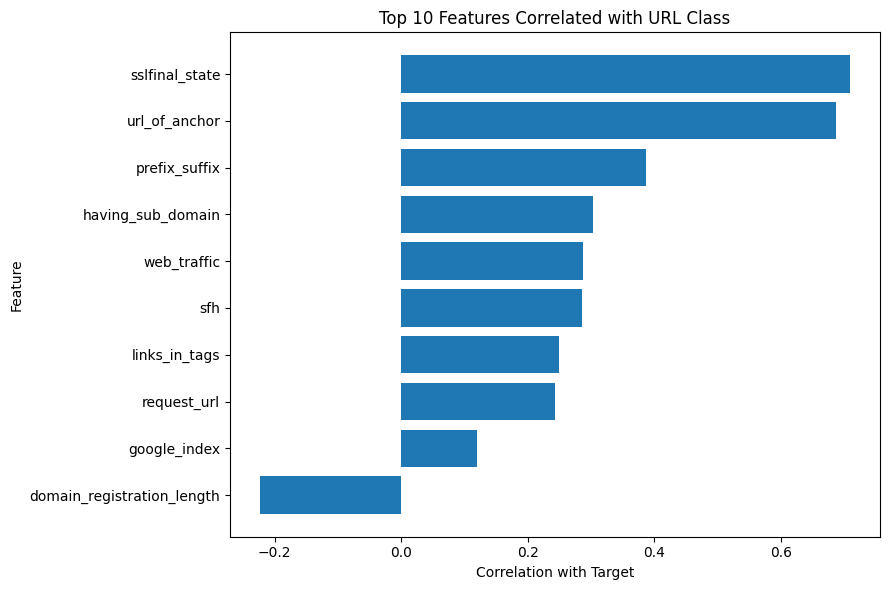

In [16]:
# Step 13: Top 10 Feature Correlations

top_corr = correlations.loc[top_features.index].sort_values()

plt.figure(figsize=(9, 6))

plt.barh(
    top_corr.index,
    top_corr.values
)

plt.title('Top 10 Features Correlated with URL Class')
plt.xlabel('Correlation with Target')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [17]:
# Step 14: Prepare Data for Machine Learning

from sklearn.model_selection import train_test_split

# Separate features and target
X_model = df_clean.drop('result', axis=1)
y_model = df_clean['result']

# Convert target:
# -1 = Phishing  -> 1
#  1 = Legitimate -> 0
y_model = y_model.map({-1: 1, 1: 0})

print("Features shape:", X_model.shape)
print("Target shape:", y_model.shape)

print("\nTarget distribution:")
print(y_model.value_counts())

print("\nTarget meaning:")
print("0 = Legitimate")
print("1 = Phishing")

Features shape: (5721, 30)
Target shape: (5721,)

Target distribution:
result
1    2955
0    2766
Name: count, dtype: int64

Target meaning:
0 = Legitimate
1 = Phishing


In [18]:
# Step 15: Split Dataset into Training and Testing Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (4576, 30)
Testing data shape: (1145, 30)

Training target distribution:
result
1    2364
0    2212
Name: count, dtype: int64

Testing target distribution:
result
1    591
0    554
Name: count, dtype: int64


In [19]:
# Step 16: Logistic Regression Model

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression pipeline
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [20]:
# Step 17: Evaluate Logistic Regression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

# Make predictions
y_pred_lr = logistic_model.predict(X_test)

# Get prediction probabilities
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("---------------------------")
print(f"Accuracy  : {accuracy_lr:.4f}")
print(f"Precision : {precision_lr:.4f}")
print(f"Recall    : {recall_lr:.4f}")
print(f"F1-Score  : {f1_lr:.4f}")
print(f"ROC-AUC   : {roc_auc_lr:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Results
---------------------------
Accuracy  : 0.9127
Precision : 0.9182
Recall    : 0.9120
F1-Score  : 0.9151
ROC-AUC   : 0.9771

Confusion Matrix:
[[506  48]
 [ 52 539]]


In [21]:
# Step 18: Decision Tree Model

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=10
)

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [22]:
# Step 19: Evaluate Decision Tree

# Make predictions
y_pred_dt = decision_tree_model.predict(X_test)

# Get prediction probabilities
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)
roc_auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Decision Tree Results")
print("---------------------")
print(f"Accuracy  : {accuracy_dt:.4f}")
print(f"Precision : {precision_dt:.4f}")
print(f"Recall    : {recall_dt:.4f}")
print(f"F1-Score  : {f1_dt:.4f}")
print(f"ROC-AUC   : {roc_auc_dt:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Results
---------------------
Accuracy  : 0.9397
Precision : 0.9424
Recall    : 0.9408
F1-Score  : 0.9416
ROC-AUC   : 0.9718

Confusion Matrix:
[[520  34]
 [ 35 556]]


In [23]:
# Step 20: K-Nearest Neighbors (KNN) Model

from sklearn.neighbors import KNeighborsClassifier

# Create KNN pipeline
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [24]:
# Step 21: Evaluate KNN

# Make predictions
y_pred_knn = knn_model.predict(X_test)

# Get prediction probabilities
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("KNN Results")
print("-----------")
print(f"Accuracy  : {accuracy_knn:.4f}")
print(f"Precision : {precision_knn:.4f}")
print(f"Recall    : {recall_knn:.4f}")
print(f"F1-Score  : {f1_knn:.4f}")
print(f"ROC-AUC   : {roc_auc_knn:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

KNN Results
-----------
Accuracy  : 0.9240
Precision : 0.9172
Recall    : 0.9374
F1-Score  : 0.9272
ROC-AUC   : 0.9765

Confusion Matrix:
[[504  50]
 [ 37 554]]


In [25]:
# Step 22: Model Comparison

model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN'
    ],
    'Accuracy': [
        accuracy_lr,
        accuracy_dt,
        accuracy_knn
    ],
    'Precision': [
        precision_lr,
        precision_dt,
        precision_knn
    ],
    'Recall': [
        recall_lr,
        recall_dt,
        recall_knn
    ],
    'F1-Score': [
        f1_lr,
        f1_dt,
        f1_knn
    ],
    'ROC-AUC': [
        roc_auc_lr,
        roc_auc_dt,
        roc_auc_knn
    ]
})

# Convert scores to percentages
model_results_display = model_results.copy()

for column in [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]:
    model_results_display[column] = (
        model_results_display[column] * 100
    ).round(2)

print("Model Comparison:")
display(model_results_display)

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,91.27,91.82,91.20,91.51,97.71
1,Decision Tree,93.97,94.24,94.08,94.16,97.18
2,KNN,92.40,91.72,93.74,92.72,97.65


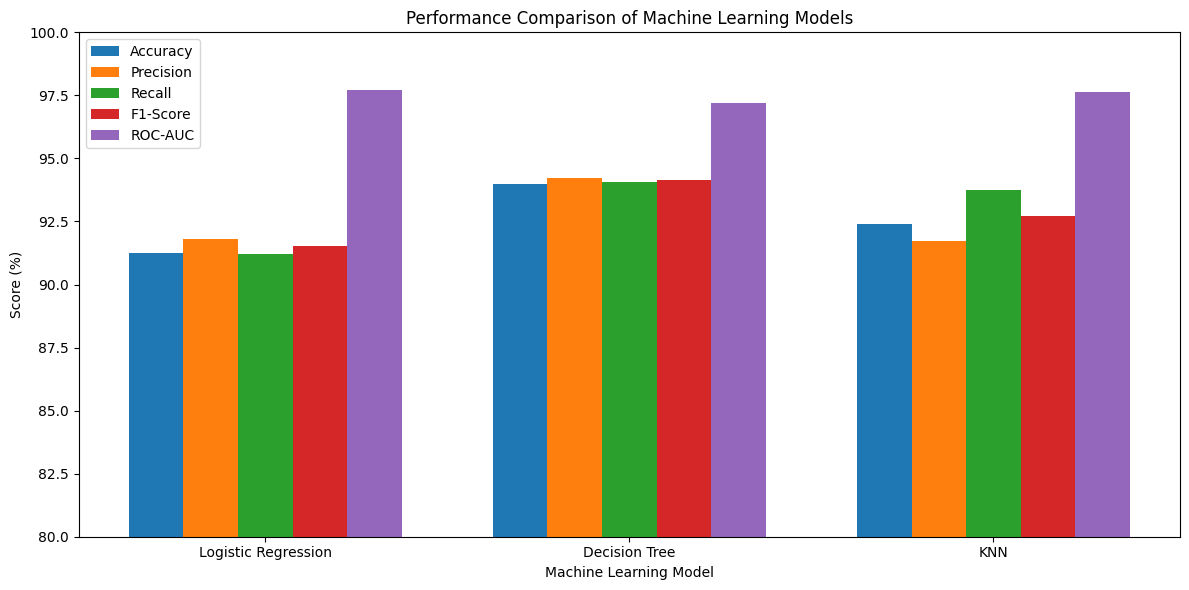

In [26]:
# Step 23: Model Performance Comparison Graph

import matplotlib.pyplot as plt
import numpy as np

models = model_results['Model']

accuracy_values = model_results['Accuracy'] * 100
precision_values = model_results['Precision'] * 100
recall_values = model_results['Recall'] * 100
f1_values = model_results['F1-Score'] * 100
roc_auc_values = model_results['ROC-AUC'] * 100

x = np.arange(len(models))
width = 0.15

plt.figure(figsize=(12, 6))

plt.bar(x - 2*width, accuracy_values, width, label='Accuracy')
plt.bar(x - width, precision_values, width, label='Precision')
plt.bar(x, recall_values, width, label='Recall')
plt.bar(x + width, f1_values, width, label='F1-Score')
plt.bar(x + 2*width, roc_auc_values, width, label='ROC-AUC')

plt.xticks(x, models)
plt.ylabel('Score (%)')
plt.xlabel('Machine Learning Model')
plt.title('Performance Comparison of Machine Learning Models')
plt.ylim(80, 100)
plt.legend()

plt.tight_layout()
plt.show()

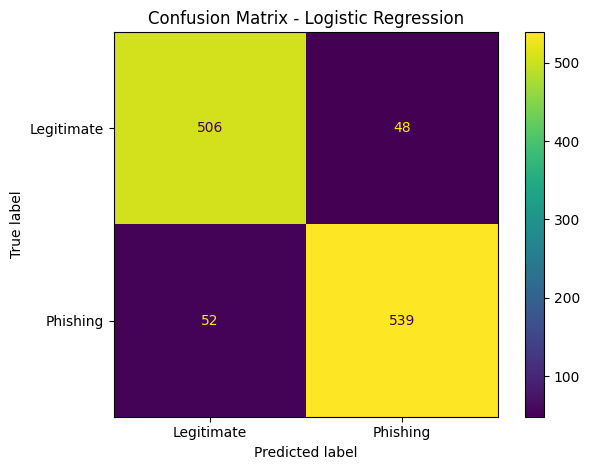

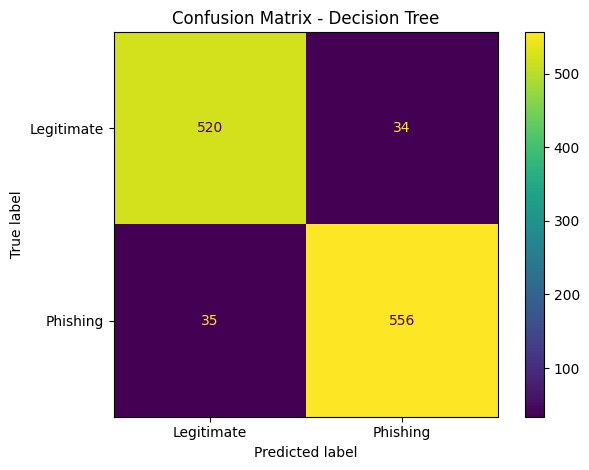

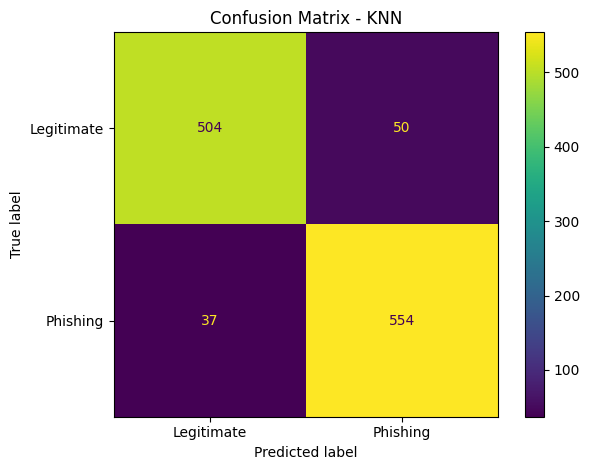

In [27]:
# Step 24: Confusion Matrix Visualization

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=['Legitimate', 'Phishing']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.tight_layout()
plt.show()


# Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=['Legitimate', 'Phishing']
)

plt.title('Confusion Matrix - Decision Tree')
plt.tight_layout()
plt.show()


# KNN
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=['Legitimate', 'Phishing']
)

plt.title('Confusion Matrix - KNN')
plt.tight_layout()
plt.show()

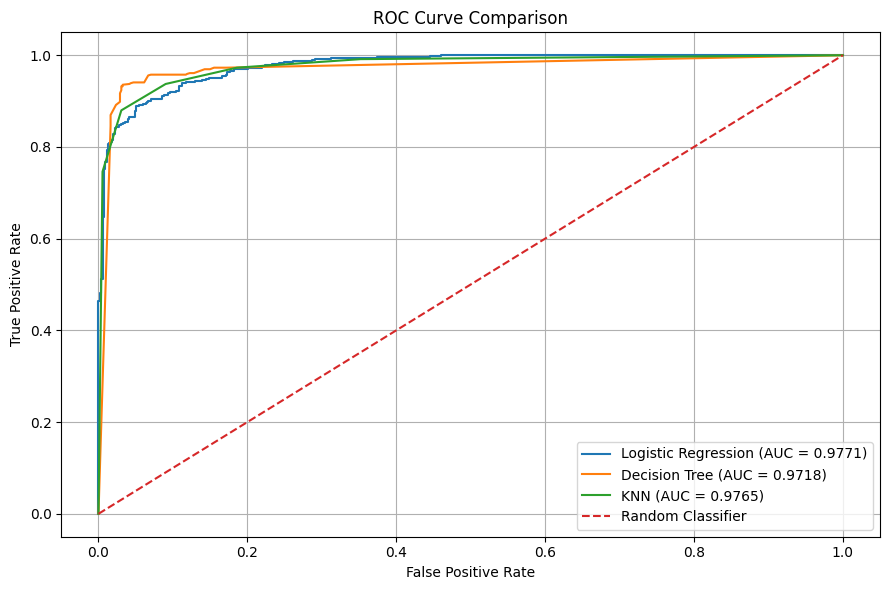

ROC-AUC Values:
Logistic Regression : 0.9771
Decision Tree       : 0.9718
KNN                 : 0.9765


In [28]:
# Step 25: ROC Curve Comparison

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)

# Calculate AUC
auc_lr = auc(fpr_lr, tpr_lr)
auc_dt = auc(fpr_dt, tpr_dt)
auc_knn = auc(fpr_knn, tpr_knn)

# Plot ROC curves
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f'Logistic Regression (AUC = {auc_lr:.4f})'
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree (AUC = {auc_dt:.4f})'
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f'KNN (AUC = {auc_knn:.4f})'
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("ROC-AUC Values:")
print(f"Logistic Regression : {auc_lr:.4f}")
print(f"Decision Tree       : {auc_dt:.4f}")
print(f"KNN                 : {auc_knn:.4f}")

In [29]:
# Step 26: Save the Decision Tree Model

import joblib

# Save trained model
joblib.dump(
    decision_tree_model,
    'phishing_decision_tree_model.pkl'
)

# Save feature names
joblib.dump(
    X_model.columns.tolist(),
    'phishing_feature_names.pkl'
)

print("Model saved successfully!")
print("Model file: phishing_decision_tree_model.pkl")
print("Feature names file: phishing_feature_names.pkl")

Model saved successfully!
Model file: phishing_decision_tree_model.pkl
Feature names file: phishing_feature_names.pkl


In [30]:
# Step 27: Check Required Project Files

import os

required_files = [
    'phishing_decision_tree_model.pkl',
    'phishing_feature_names.pkl',
    'phishing_cleaned.csv'
]

print("Project Files:")
print("----------------")

for file in required_files:
    if os.path.exists(file):
        size = os.path.getsize(file) / 1024
        print(f"✅ {file} ({size:.2f} KB)")
    else:
        print(f"❌ {file} - NOT FOUND")

Project Files:
----------------
✅ phishing_decision_tree_model.pkl (25.35 KB)
✅ phishing_feature_names.pkl (0.48 KB)
✅ phishing_cleaned.csv (402.17 KB)


In [32]:
# Step 27A: Get one real test record for Streamlit testing

test_sample = X_test.iloc[0].copy()

print("Test sample feature values:")
print(test_sample)

print("\nActual target:")
print(y_test.iloc[0])

print("\nTarget meaning:")
if y_test.iloc[0] == 1:
    print("Phishing")
else:
    print("Legitimate")

Test sample feature values:
having_ip_address             1
url_length                   -1
shortining_service            1
having_at_symbol              1
double_slash_redirecting      1
prefix_suffix                -1
having_sub_domain            -1
sslfinal_state               -1
domain_registration_length   -1
favicon                      -1
port                         -1
https_token                   1
request_url                   1
url_of_anchor                 0
links_in_tags                -1
sfh                          -1
submitting_to_email          -1
abnormal_url                  1
redirect                      0
on_mouseover                  1
rightclick                    1
popupwindow                  -1
iframe                        1
age_of_domain                 1
dnsrecord                     1
web_traffic                   1
page_rank                    -1
google_index                 -1
links_pointing_to_page        0
statistical_report            1
Name: 1501, 